# Construção de Raciocínio e Justificativa

Diante do panorama explorado no primeiro bloco e da constatação dos limites impostos pela baixa densidade estatística, a investigação exigiu um contraponto empírico: a transição para um novo dataset. Selecionamos uma base que preserva o mesmo domínio temático — fatores socioeconômicos e acadêmicos que afetam a trajetória de estudantes —, mas que altera substancialmente a relação entre volume e complexidade. Em vez de estimar uma nota fragmentada em oito categorias com pouco mais de uma centena de exemplos, o novo cenário propõe a classificação do status acadêmico final em três classes bem delineadas: evasão (Dropout), matriculado (Enrolled) ou graduado (Graduated).

A principal motivação técnica para essa escolha reside na escala dos dados. Contando com 4.424 instâncias — um aumento de quase quarenta vezes em relação à amostra anterior —, o novo conjunto fornece a densidade necessária para alimentar a matemática iterativa das Redes Neurais, testando de forma direta a hipótese da 'fome de dados' levantada anteriormente. Além disso, por apresentar atributos de naturezas distintas (real, categorical e integer), este segundo experimento introduz uma nova camada de rigor metodológico, exigindo etapas complementares de pré-processamento (como a codificação de variáveis qualitativas via One-Hot Encoding) antes da padronização e do retreinamento dos modelos.

In [14]:
# tratamento de dados pt1

import pandas as pd

df = pd.read_csv('../dados/raw/data.csv', sep=';')

df.head(5)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [9]:
# tratamento de dados pt2

from sklearn.preprocessing import LabelEncoder

print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas")
print(f"Total de valores ausentes (NaN): {df.isnull().sum().sum()}")

coluna_alvo = 'Target' if 'Target' in df.columns else df.columns[-1]
print(f"\nDistribuição das classes na coluna '{coluna_alvo}':")
print(df[coluna_alvo].value_counts())

X = df.drop(columns=[coluna_alvo])
y = df[coluna_alvo]

# Mapeamento do alvo categórico para números (Dropout=0, Enrolled=1, Graduated=2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nMapeamento das classes:")
for classe, codigo in zip(le.classes_, range(len(le.classes_))):
    print(f"Classe '{classe}' -> Código {codigo}")

Dimensões do dataset: 4424 linhas e 37 colunas
Total de valores ausentes (NaN): 0

Distribuição das classes na coluna 'Target':
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Mapeamento das classes:
Classe 'Dropout' -> Código 0
Classe 'Enrolled' -> Código 1
Classe 'Graduate' -> Código 2


# Análise de "tratamento de dados pt2".

A etapa de pré-processamento do segundo conjunto de dados consolidou os princípios teóricos estabelecidos no primeiro experimento, adaptando-os a uma estrutura mais complexa. 

Inicialmente, realizou-se uma varredura exploratória na matriz para aferir a integridade dos dados, constatando-se a ausência de registros nulos ou faltantes, o que dispensou o uso de métodos de imputação estatística. Diferentemente do primeiro dataset, no qual foi necessária a intervenção manual para extirpar variáveis de identificação administrativa (como STUDENT_ID), esta base apresentou uma arquitetura integralmente orientada ao domínio do problema: todas as colunas representam fatores demográficos, socioeconômicos e notas de semestres curriculares.

A seguir, procedeu-se à separação formal entre a matriz de atributos preditivos (X) e o vetor gabarito (y). Como o nosso alvo (Target) era composto por rótulos qualitativos em formato textual (Dropout, Enrolled e Graduated), fez-se necessária a aplicação do LabelEncoder. Essa transformação mapeia cada categoria semântica para um identificador inteiro discreto (0, 1 e 2), viabilizando o cálculo matricial exigido pela camada de saída das Redes Neurais sem alterar a relação estatística entre as classes. 

Durante a análise minuciosa da estrutura do segundo dataset, emergiu uma preocupação metodológica quanto à integridade das representações numéricas: variáveis essencialmente nominais — como profissões e cursos — foram pré-codificadas na base original por meio de inteiros arbitrários (atribuindo, por exemplo, o valor 3 para técnicos intermediários e 131 para profissões da saúde). Sob a ótica do cálculo vetorial das Redes Neurais, onde as entradas são diretamente multiplicadas por pesos sinápticos (w.xi), essa discretização impõe uma falsa relação de ordem e distância euclidiana inexistente no mundo real, risco que a padronização via StandardScaler apenas reescala na reta contínua sem anular a distorção relacional.

Contudo, induz-se que o modelo não colapsou diante dessas falsas hierarquias porque o núcleo do sinal preditivo não repousa nas variáveis demográficas acessórias, mas sim em atributos acadêmicos e financeiros intrinsecamente quantitativos ou binários — tais como o número de unidades curriculares aprovadas no primeiro e segundo semestres, notas médias e a adimplência com as mensalidades —, cujo peso matemático suplantou eventuais ruídos causados pela codificação inadequada das profissões.

Conclui-se, portanto, a hipótese de que, embora a densidade de mais de quatro mil instâncias tenha sido suficiente para que as camadas ocultas do MLP acomodassem essas imperfeições geométricas e validassem nossa tese central de volume amostral, a conversão futura desses atributos nominais via One-Hot Encoding permanece como a principal via de refinamento metodológico para extirpar vieses artificiais e extrair a máxima acurácia da arquitetura.

Por fim, identificou-se que, embora a maioria dos atributos preditivos já estivesse discretizada em números inteiros e reais, eles operam sob intervalos matemáticos discrepantes (como idade, taxas de inflação e unidades curriculares cursadas), ratificando que a etapa subsequente de partição (treino/teste) e a padronização via escore-z (StandardScaler) serão novamente indispensáveis para assegurar a convergência numérica dos modelos.


In [13]:
# treinamento pt1 (MLP route)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded
)

# Padronização das variáveis preditivas (escore-z)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Definição da arquitetura MLP
mlp = MLPClassifier(
    hidden_layer_sizes=(20,), 
    activation='relu', 
    solver='adam', 
    max_iter=1000, 
    random_state=42
)

# Treino e Avaliação
mlp.fit(X_train_scaled, y_train)
previsoes_mlp = mlp.predict(X_test_scaled)
acuracia_mlp = accuracy_score(y_test, previsoes_mlp)

print(f"Acurácia do MLP: {acuracia_mlp * 100:.2f}%\n")
print("Relatório de Classificação:")
print(classification_report(y_test, previsoes_mlp, target_names=le.classes_))

Acurácia do MLP no novo dataset: 72.66%

Relatório de Classificação:
              precision    recall  f1-score   support

     Dropout       0.76      0.73      0.74       284
    Enrolled       0.43      0.36      0.40       159
    Graduate       0.79      0.85      0.82       442

    accuracy                           0.73       885
   macro avg       0.66      0.65      0.65       885
weighted avg       0.72      0.73      0.72       885



# Análise de "treinamento pt1 (MLP route)"

A exploração inicial dos dados revelou uma matriz composta por 4.424 observações e 37 variáveis originais, desprovida de registos ausentes. A inspecção da variável dependente evidenciou uma distribuição de 2.209 alunos diplomados, 1.421 em situação de abandono escolar e 794 com matrícula activa. Embora exista uma predominância natural da classe Graduate, as três categorias apresentam volume amostral suficiente para mitigar o colapso estatístico verificado no conjunto de dados anterior.

Para assegurar a validade metodológica da avaliação, aplicou-se a divisão do conjunto em 80% para treino e 20% para teste, introduzindo-se o parâmetro de estratificação (stratify=y_encoded). 

Ao contrário de uma divisão puramente aleatória, a amostragem estratificada preserva rigorosamente as proporções relativas de cada categoria do alvo em ambos os subconjuntos, impedindo que classes minoritárias (como os estudantes ainda matriculados) fiquem sub-representadas na base de teste. Subsequentemente, empregou-se o StandardScaler ajustado unicamente sobre a partição de treino e transposto para o teste, prevenindo o data leakage.

Com a matriz devidamente padronizada e com densidade de instâncias suficiente, procedeu-se à reintrodução do algoritmo Multi-Layer Perceptron. Desta feita, utilizou-se o algoritmo de optimização estocástica adam, testando diretamente a hipótese formulada no primeiro bloco de trabalho: munido de uma base amostral robusta e livre de sobreposições extremas de classes, o estimador baseado em gradientes estocásticos atinge a estabilização matemática sem esgotar iterações e sem recorrer a previsões enviesadas numa única classe maioritária.


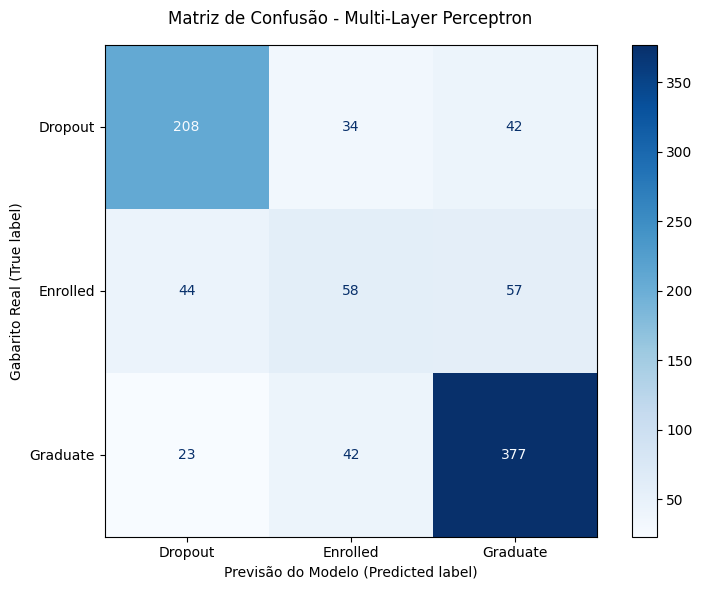

In [15]:
# treinamento pt2 (MLP + Confusion Matrix)

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, previsoes_mlp)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax)

plt.title("Matriz de Confusão - Multi-Layer Perceptron", pad=15)
plt.xlabel("Previsão do Modelo (Predicted label)")
plt.ylabel("Gabarito Real (True label)")

plt.tight_layout()
plt.show()

# Análise de "treinamento pt1 (MLP route) + treinamento pt2 (MLP + Confusion Matrix)

A execução do Multi-Layer Perceptron sobre a nova base de dados apresentou uma inflexão metodológica decisiva no projeto: a acurácia saltou de modestos 20,69% observados no primeiro dataset para expressivos 72,66%. Além do ganho absoluto de desempenho, o otimizador estocástico adam convergiu com estabilidade matemática, operando sem a emissão de alertas de esgotamento de iterações (ConvergenceWarning). Esse resultado valida empiricamente a hipótese da 'fome de dados' (Data Hunger) formulada nas etapas anteriores: quando munida de uma amostragem robusta (mais de 3.500 instâncias de treino), a rede neural é capaz de ajustar suas matrizes de pesos sem recorrer à memorização de ruídos (overfitting) nem à aposta cega em uma única classe dominante.

Com o intuito de visualizarmos melhor o sucesso do MLP nesse dataset, exploramos as métricas seguido da matriz de confusão para melhor didática:

I. O modelo demonstrou alta capacidade de discriminação nas classes que representam desfechos consolidados. A classe Graduate obteve precisão de 0,79 e revocação (recall) de 0,85 (F1-score de 0,82), enquanto Dropout alcançou precisão de 0,76 e revocação de 0,73 (F1-score de 0,74). 

II. Um fator que chamou atenção foi em relação a classe dos alunos matriculados (Enrolled), que obteve métricas sensivelmente inferiores (precisão de 0,43 e revocação de 0,36). Teorizamos que a baixa assertividade da categoria decorre de 2 principais fatores: A sua natureza transitória e o número de instâncias desbalanceadas.

Diferente de Graduate e Dropout, que representam desfechos consolidados com "assinaturas" matemáticas marcantes (como a conclusão de todas as disciplinas ou a inadimplência somada a reprovações), o estado "matriculado" não possui um agrupamento (cluster) isolado. Ele é um estado transitório cujos atributos inevitavelmente se sobrepõem às características de quem está caminhando para o sucesso ou para a desistência, tornando as fronteiras de decisão do MLP difusas e propensas a espalhar os erros de forma quase equitativa entre os outros dois desfechos.

O outro fator citado, é que a classe Enrolled é a minoria absoluta do dataset, apenas 794, frente as mais de 2200 de Graduate. Se houvessemos mais exemplares em tal classe, a rede neural provavelmente daria o mesmo "peso" matemático aos erros cometidos nela durante a atualização do gradiente, impedindo que o modelo a negligenciasse em favor da classe majoritária.

Para a Matriz de Confusão, a diagonal principal confirma a solidez na aprendizagem com 377 acertos para Graduate e 208 pra Dropout. Entretanto, a linha central valida justamente a hipótese sobre a classe Enrolled: temos 44 previsões erradas para Dropout, apenas 58 acertos na classe correta e 57 falsos positivos para Graduate.

Acurácia da Árvore de Decisão: 69.49%
Acurácia do Random Forest:   76.38%



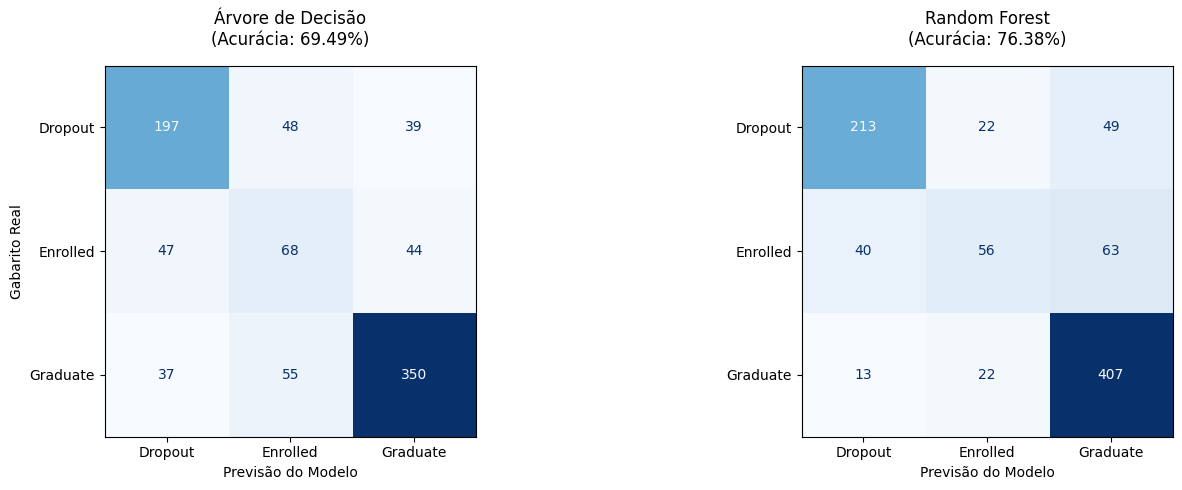

In [16]:
# treinamento pt3 (Decision Tree + Random Forest)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# Instanciando os modelos 
dt = DecisionTreeClassifier(random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Treinamento utilizando os dados já padronizados do MLP
dt.fit(X_train_scaled, y_train)
rf.fit(X_train_scaled, y_train)

# 3. Previsões e cálculo de Acurácia
prev_dt = dt.predict(X_test_scaled)
prev_rf = rf.predict(X_test_scaled)

acc_dt = accuracy_score(y_test, prev_dt)
acc_rf = accuracy_score(y_test, prev_rf)

print(f"Acurácia da Árvore de Decisão: {acc_dt * 100:.2f}%")
print(f"Acurácia do Random Forest:   {acc_rf * 100:.2f}%\n")

# Plotagem comparativa das Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Matriz Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, prev_dt, display_labels=le.classes_, cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title(f"Árvore de Decisão\n(Acurácia: {acc_dt*100:.2f}%)", pad=15)
axes[0].set_xlabel("Previsão do Modelo")
axes[0].set_ylabel("Gabarito Real")

# Matriz Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, prev_rf, display_labels=le.classes_, cmap='Blues', ax=axes[1], colorbar=False
)
axes[1].set_title(f"Random Forest\n(Acurácia: {acc_rf*100:.2f}%)", pad=15)
axes[1].set_xlabel("Previsão do Modelo")
axes[1].set_ylabel("") # Remove o label Y da segunda para ficar mais limpo

plt.tight_layout()
plt.show()

# Análise de "treinamento pt3 (Decision Tree + Random Forest)"

Para selar nosso bloco de conclusões, julgamos necessário fazer um teste de controle extra submetendo os algoritmos baseados em árvores (Decision Tree e Random Forest) — que haviam colapsado no primeiro experimento com acurácias inferiores a 18% — a esta nova base de dados de alta densidade. O objetivo metodológico era isolar a variável 'volume amostral'; caso o desempenho de ambos os modelos sofresse um salto qualitativo alinhado ao observado nas Redes Neurais, restaria comprovado que a falha inicial decorreu exclusivamente da escassez estatística da matriz original, e não de uma inaptidão das arquiteturas.

A submissão dos algoritmos baseados em árvores ao novo ecossistema de dados ratificou a tese central deste estudo. A Árvore de Decisão alcançou 69,49% de acurácia, enquanto o conjunto do Random Forest estabeleceu o novo teto de desempenho do experimento com 76,38%. A capacidade do modelo de discriminar as classes consolidadas demonstrou-se robusta, evidenciada pelos 407 acertos absolutos na predição de alunos graduados e 213 acertos para as evasões. Esse contraste flagrante com o colapso generalizado observado no primeiro conjunto de dados comprova que a complexidade algorítmica é matematicamente inútil na ausência de densidade amostral e de sinais preditivos estruturados.

Ademais, a estagnação do limite superior de acurácia na faixa dos 76% ilustra os desafios inerentes à modelagem do comportamento humano. A persistência de erros na classificação do estado transitório ('matriculado'), que ainda sofreu dispersão entre previsões de evasão (40 ocorrências) e graduação (63 ocorrências), sugere que a arquitetura dos modelos atingiu o limite do que os dados brutos têm a oferecer.

# Análise de "treinamento pt4 (Naive-Bayes from scratch route)

Como forma de confirmar todos os nossos vieses, executamos novamente o Naive-Bayes programado manualmente mas com a nova base de dados, verificando-se de forma previsível a maior acurácia.

Acurácia: 69.27%


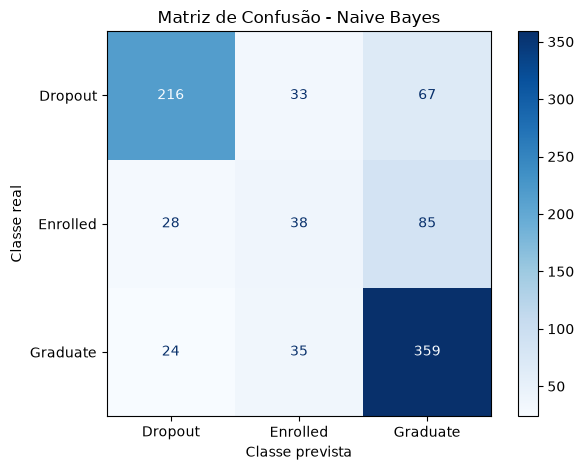


Matriz de Confusão:
[[216  33  67]
 [ 28  38  85]
 [ 24  35 359]]
Acurácia: 69.27%


In [1]:
# treinamento pt8 (Naive-Bayes from scratch route)

from pandas import DataFrame, read_csv
from math import sqrt, exp, pi, log
from sklearn.model_selection import train_test_split 
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def prob_naive_produtorio(x, media, desvio, prio):

    #Recebe as entradas como listas.

    prob = log(prio)
    for i in range(len(x)):

        #Verifica se o desvio é igual a zero antes de soma-lo

        if desvio[i] != 0.0:

            #Realiza a soma com logaritimos para evitar overflow

            prob += -log(desvio[i] * sqrt(2*pi)) - ((x[i]-media[i])**2/(2*(desvio[i]**2)))
        else:
            prob += 1e-9

    return prob

def naive_bayes(base_treino, base_testes):

    #Recebe um DataFrame (M x N) de treino do tipo pandas, onde a ultima coluna armazena as categorias.
    #Recebe um DataFrame para testes do tipo pandas onde cada linha se refere a um objeto.

    #Retorna uma lista com a previsao de saida de cada objeto na mesma ordem do DataFrame de testes.

    N = base_treino.shape[1]
    
    categorias = base_treino.iloc[:, -1].unique().tolist()

    medias = []
    desvios = []
    proporcao = []

    for cat in categorias:
        linhas_categoria = base_treino[base_treino.iloc[ : , -1] == cat]
        medias.append(linhas_categoria.iloc[ : , :-1].mean().tolist())
        desvios.append(linhas_categoria.iloc[ : , :-1].std().tolist())
        proporcao.append(len(linhas_categoria)/len(base_treino))

    saida = []


    for i in range(base_testes.shape[0]):
        maior_prob = float('-inf')
        categoria = 0
        for j in range(len(categorias)):
            prob = prob_naive_produtorio(base_testes.iloc[i, :N-1].tolist(), medias[j], desvios[j], proporcao[j])
            if prob > maior_prob:
                maior_prob = prob
                categoria = j
        saida.append(categorias[categoria])

    return saida

#---------INDICADORES------------
#---------INDICADORES------------

def acuracia(base, saida):
    acuracia = 0
    for i in range(len(saida)):
        if saida[i] == base.iloc[i, -1]:
            acuracia += 1

    return acuracia / len(saida)


def matriz_confusao(base, saida, categorias):

    # Valores reais
    valores_reais = base.iloc[:, -1]

    # Calcula a matriz de confusão
    matriz = confusion_matrix(
        valores_reais,
        saida,
        labels=categorias
    )

    # Configura a visualização
    exibicao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=categorias
    )

    exibicao.plot(cmap="Blues", values_format="d")

    plt.title("Matriz de Confusão - Naive Bayes")
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.tight_layout()
    plt.show()

    return matriz
def acuracia(base, saida):
    acuracia = 0
    for i in range(len(saida)):
        if saida[i] == base.iloc[i, -1]:
            acuracia +=1
    
    return acuracia/len(saida)



#---------ZONA DE TESTES---------

from pandas import DataFrame, read_csv
from sklearn.model_selection import train_test_split

#---------ZONA DE TESTES---------

data_2 = read_csv("../dados/raw/data.csv", sep=";")

x_treino, x_teste, y_treino, y_teste = train_test_split(
    data_2.iloc[:, :-1],
    data_2.iloc[:, -1],
    test_size=0.2,
    random_state=42
)

data_treino = DataFrame(data=x_treino)
data_treino["target"] = y_treino

data_teste = DataFrame(data=x_teste)
data_teste["target"] = y_teste

previsao = naive_bayes(data_treino, data_teste)

print(f"Acurácia: {acuracia(data_teste, previsao)*100:.2f}%")

categorias = data_treino["target"].unique().tolist()

matriz = matriz_confusao(data_teste, previsao, categorias)

print("\nMatriz de Confusão:")
print(matriz)

data_2 = read_csv("../dados/raw/data.csv", sep=";")

x_treino, x_teste, y_treino, y_teste = train_test_split(
    data_2.iloc[:, :-1], 
    data_2.iloc[:, -1], 
    test_size=0.2, 
    random_state=42
)

data_treino = DataFrame(data = x_treino)
data_treino["target"] = y_treino

data_teste = DataFrame(data = x_teste)
data_teste["target"] = y_teste

previsao = naive_bayes(data_treino, data_teste)

print(f"Acurácia: {acuracia(data_teste, previsao)*100:.2f}%")